<a href="https://colab.research.google.com/github/revak18/science_fair_2026/blob/main/science_fair_2026_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# @title 1. SETUP & CONFIGURATION (REFINED)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive, userdata

# 1. MOUNT & DIRECTORIES
drive.mount("/content/drive")
BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
HOURLY_LOAD_DIR = os.path.join(BASE_DIR, "hourly_load_raw")
WATER_IMPACT_DIR = os.path.join(BASE_DIR, "water_impact_raw")
RESULTS_FILE = "final_scientific_results_optimized.csv"

for d in [BASE_DIR, HOURLY_LOAD_DIR, WATER_IMPACT_DIR]:
    os.makedirs(d, exist_ok=True)

# 2. GLOBAL STUDY PARAMETERS
REGIONS = ["PJME"]               # Region for study
AI_LOAD_LEVELS = [0.10,0.20]     # High load level to ensure visible impact
N_TRIALS = 2                     # High trials for statistical robustness
HORIZON_HOURS = 48               # 48h window for job flexibility
PLANT_SIZE_MW = 500.0            # Benchmark for "Plants Saved" metric
DROUGHT_FACTOR = 1.0             # 1.0 = Normal, 1.2+ = Drought

# 3. PARETO & SOLVER SETTINGS
# Use Log-scale weights to ensure the solver reacts to water
PARETO_WEIGHTS = [0.0, 1e-5, 1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

# "Stressor" Constants to force the Gas vs. Water trade-off
# 0.8 to 0.9	Robust Grid: The grid is strong and has plenty of spare capacity.
# 0.5 Stressed Grid: This simulates a "Peak Day" scenario where existing clean energy is pushed to its limit.
# 0.2 to 0.3	Emergency/Crisis: The grid has very little baseload capacity available.
STRESS_ALPHA = 0.6               # 60% base capacity forces Gas use


IMPORT_LIMIT_MW = 5000.0         # Grid interconnections
SLACK_REGIME = "tight"           # "tight": (1-4h) | "medium": (6-12h) | "loose": (12-24h) window for job movement

# 4. KAGGLE CREDENTIALS
try:
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print("Kaggle credentials loaded securely.")
except Exception:
    print("Warning: Kaggle credentials not found in Secrets.")

print(f"Setup Complete. Results will save to: {RESULTS_FILE}")

Mounted at /content/drive
Kaggle credentials loaded securely.
Setup Complete. Results will save to: final_scientific_results_optimized.csv


In [2]:
# @title 2. DATA DOWNLOADERS (Run Once)
# ==========================================
# 2. DATA DOWNLOADERS (Run Once)
# ==========================================
import shutil
import zipfile

def download_data_if_missing():
#     # A. Grid Load (Kaggle)
#     if not os.listdir(HOURLY_LOAD_DIR):
#         print("Downloading Grid Load Data from Kaggle...")
#         # Secure system call using the directory from configuration
#         os.system(f'kaggle datasets download -d robikscube/hourly-energy-consumption -p "{BASE_DIR}"')
#         zip_path = os.path.join(BASE_DIR, "hourly-energy-consumption.zip")

#         if os.path.exists(zip_path):
#             with zipfile.ZipFile(zip_path, 'r') as z:
#                 z.extractall(HOURLY_LOAD_DIR)
#             print("Grid Data Extracted to hourly_load_raw.")
#         else:
#             print("Error: Zip file from Kaggle not found. Check credentials.")

    # B. Water Data (HydroShare / Manual)
    # We move the CSV into the specific sub-folder defined in Cell 1
    water_csv_name = "Water_IMPACT-Data_Consumption_2020.csv"
    water_csv_path = os.path.join(WATER_IMPACT_DIR, water_csv_name)

    if not os.path.exists(water_csv_path):
        # Check if it was accidentally downloaded to the BASE_DIR instead of WATER_IMPACT_DIR
        misplaced_path = os.path.join(BASE_DIR, water_csv_name)
        if os.path.exists(misplaced_path):
            print("Moving Water CSV to correct sub-directory...")
            shutil.move(misplaced_path, water_csv_path)
        else:
            print(f"CRITICAL: {water_csv_name} not found in {WATER_IMPACT_DIR}.")
            print("Please upload this file to your Drive folder manually to continue.")
    else:
        print("Water IMPACT Data verified in directory.")

download_data_if_missing()

Water IMPACT Data verified in directory.


In [4]:
# @title 3. DATA LOADERS (REFINED FOR OPTIMIZED WORKFLOW)
import pandas as pd
import numpy as np
import os
from datetime import timedelta

def load_ba_load(region: str):
    """Loads Grid Load with explicit cleaning and reindexing."""
    print(f"   -> Loading Grid Load for {region}...")
    fname = f"{region}_hourly.csv"
    path = os.path.join(HOURLY_LOAD_DIR, fname)

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    # Parse and rename
    df = pd.read_csv(path, parse_dates=["Datetime"])
    mw_col = [c for c in df.columns if c.endswith("_MW")]
    if not mw_col:
        raise ValueError(f"No *_MW column found in {path}")
    df = df.rename(columns={mw_col[0]: "load_MW"})

    # Clean indices and deduplicate
    df = df.set_index("Datetime").sort_index()
    df["load_MW"] = pd.to_numeric(df["load_MW"], errors="coerce")
    df = df.groupby(df.index).mean(numeric_only=True)

    # Reindex to full hourly timeline (fixed 'h' frequency)
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
    df = df.reindex(full_idx)

    # Clean outliers and fill gaps
    df.loc[df["load_MW"] < 0, "load_MW"] = np.nan
    lo, hi = df["load_MW"].quantile(0.001), df["load_MW"].quantile(0.999)
    df["load_MW"] = df["load_MW"].clip(lo, hi).interpolate(limit=3).ffill().bfill()

    return df


def load_water_intensity(region: str):
    """Loads Water Data mapped to BA regions."""
    print(f"   -> Loading Water Intensity for {region}...")

    REGION_MAP = {
        "PJME": "PJM", "PJMW": "PJM", "COMED": "PJM", "DAYTON": "PJM",
        "AEP": "PJM", "DOM": "PJM", "DUQ": "PJM", "FE": "PJM",
        "DEOK": "PJM", "NI": "PJM", "PJM": "PJM",
        "CISO": "CISO", "ERCOT": "ERCO", "SPP": "SWPP"
    }
    search_region = REGION_MAP.get(region, region)

    # Path check aligned with refined Setup
    path = os.path.join(WATER_IMPACT_DIR, "Water_IMPACT-Data_Consumption_2020.csv")
    if not os.path.exists(path):
        raise FileNotFoundError(f"Water file not found at {path}")

    df = pd.read_csv(path, parse_dates=["date"])

    # Filter and process BA-specific water intensity
    ba_col = "balancing_authority" if "balancing_authority" in df.columns else "ba_code"
    df = df[df[ba_col] == search_region].copy()
    if df.empty:
        raise ValueError(f"Region '{search_region}' not found in Water Data.")

    df = df.set_index("date").sort_index()
    df = df.groupby(df.index).mean(numeric_only=True)

    # Units: l/kWh to m3/MWh (1:1 conversion)
    target = "wci_primary" if "wci_primary" in df.columns else "w_consume_l_per_kwh"
    df["w_m3_per_MWh"] = pd.to_numeric(df[target], errors="coerce") * float(DROUGHT_FACTOR)

    # Final cleaning and resampling (fixed 'h' frequency)
    hi = float(df["w_m3_per_MWh"].quantile(0.999))
    df_clean = df[["w_m3_per_MWh"]].clip(0, hi).resample("h").mean()
    df_clean["w_m3_per_MWh"] = df_clean["w_m3_per_MWh"].interpolate(limit=3).ffill().bfill()

    return df_clean


def build_stressed_window(load_df, water_df, horizon_hours, top_k_candidates=50):
    """Extracts a high-load peak window for regional study."""
    print(f"   -> Extracting Peak {horizon_hours}h Window...")

    # Helper to ensure windows don't overlap too much
    def _dedupe_candidates(times, sep_hrs):
        kept = []
        for t in times:
            if all(abs((t - k).total_seconds()) >= sep_hrs * 3600 for k in kept):
                kept.append(t)
        return kept

    # 7-day rolling mean to identify seasonal peak
    rolling = load_df["load_MW"].rolling(window=24*7, min_periods=24).mean()
    if rolling.dropna().empty:
        raise ValueError("Load data insufficient for window extraction.")

    candidate_times = list(rolling.nlargest(top_k_candidates).index)
    candidate_times = _dedupe_candidates(candidate_times, 24)

    target_year = int(water_df.index.year[0]) # Align with 2020 water data

    for rank, peak_time in enumerate(candidate_times, start=1):
        # Center the window around the peak time
        start = peak_time - timedelta(hours=horizon_hours // 2)
        end = start + timedelta(hours=horizon_hours - 1)

        load_slice = load_df.loc[start:end].copy()
        if len(load_slice) < horizon_hours:
            continue

        # Year-shifting to match 2020 Water Impact dataset
        try:
            load_slice.index = [d.replace(year=target_year) for d in load_slice.index]
        except ValueError: # Handle leap day issues
            load_slice.index = [d.replace(year=target_year, month=3, day=1) if (d.month==2 and d.day==29) else d.replace(year=target_year) for d in load_slice.index]

        # Merge Load and Water
        window_df = pd.DataFrame(index=load_slice.index)
        window_df["L_base_MW"] = load_slice["load_MW"].values
        window_df["water_m3_per_mwh"] = water_df["w_m3_per_MWh"].reindex(window_df.index).interpolate(limit=3).ffill().bfill().values

        if not window_df.isna().any().any():
            print(f"      Selected window starting {start} (Rank #{rank})")
            return window_df

    raise ValueError(f"Could not find a valid {horizon_hours}h window for this region.")

In [22]:
# @title 4. FINAL CALIBRATED & OPTIMIZED SOLVER (PRODUCTION)
import pulp
import numpy as np

def generate_jobs_stochastic(T, t_peak, L_max, rng, ai_frac=0.10, slack_regime="tight", n_jobs=100):
    """
    Generates AI training jobs with high-precision energy scaling and strict power caps.
    """
    # 1. Configuration and Energy Targets
    target_ai_mw = L_max * ai_frac
    target_energy_mwh = target_ai_mw * T

    # 2. Sample Durations first [cite: 676, 677]
    durations = rng.integers(2, 7, size=n_jobs)

    # 3. Define Slack Ranges [cite: 666, 671]
    slack_map = {"tight": (1, 4), "medium": (6, 12), "loose": (12, 24)}
    s_min, s_max = slack_map.get(slack_regime, (1, 4))

    # 4. Build Initial Jobs with Boundary Safety [cite: 1530, 1531]
    arrivals = rng.normal(t_peak, 8, n_jobs)
    jobs = []

    # Real-world cap: no single job exceeds 5% of total deferrable AI capacity
    # job_power_cap = 0.05 * target_ai_mw

    total_dur = float(np.sum(durations))
    base_power = target_energy_mwh / total_dur

    min_cap_frac_needed = T / total_dur
    cap_frac = 0.05  # your preferred cap
    cap_frac_eff = max(cap_frac, 1.05 * min_cap_frac_needed)  # 5% buffer
    job_power_cap = cap_frac_eff * target_ai_mw




    for i in range(n_jobs):
        d_val = int(durations[i])
        # Initial guess distribution
        #p_val = (target_energy_mwh / np.sum(durations)) * rng.uniform(0.9, 1.1)

        p_val = base_power * rng.uniform(0.9, 1.1)

        p_val = min(p_val, job_power_cap) ##---------------------------------------------------------------------------

        latest_start = max(0, T - d_val)
        release = int(np.clip(arrivals[i], 0, latest_start))

        slack = rng.integers(s_min, s_max + 1)
        deadline = max(min(T, release + d_val + slack), release + d_val)

        jobs.append({"id": i, "p": p_val, "d": d_val, "r": release, "e": deadline})

    # 5. HIGH-PRECISION ITERATIVE RENORMALIZATION
    # Fix: Scale only uncapped jobs to close the energy gap
    eps = 1e-9
    for _ in range(20):
        total_energy = sum(j["p"] * j["d"] for j in jobs)
        if total_energy <= 0:
            break

        gap = target_energy_mwh - total_energy
        if abs(gap) <= 1e-6 * target_energy_mwh:
            break  # Targeted energy reached

        # Identify 'free' jobs not yet at the power cap
        free = [j for j in jobs if j["p"] < job_power_cap - eps]
        if not free:
            break # All jobs capped; cannot add more energy

        free_energy = sum(j["p"] * j["d"] for j in free)
        if free_energy <= 0:
            break

        # Scale only the free jobs to close the remaining gap
        #scale = (free_energy + gap) / free_energy
        scale = max(0.0, (free_energy + gap) / free_energy)

        hit_cap = False
        for j in free:
            j["p"] *= scale
            if j["p"] > job_power_cap:
                j["p"] = job_power_cap
                hit_cap = True

        if not hit_cap and abs(target_energy_mwh - sum(j["p"] * j["d"] for j in jobs)) <= 1e-6 * target_energy_mwh:
            break

    # Final Verification
    final_energy = sum(j["p"] * j["d"] for j in jobs)
    if final_energy < 0.99 * target_energy_mwh:
        print(f"Warning: Energy target not met ({final_energy/target_energy_mwh:.1%}). "
              "Check if n_jobs or job_power_cap is too low.")

    return jobs

def solve_milp_with_schedule(L_base, L_online, jobs, w_vec, alpha=0.6, rho=0.15,
                             water_weight=0.0, import_limit_MW=0.0):
    """
    High-performance MILP Solver with precomputed job lookups and robust extraction.
    """
    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex_Final", pulp.LpMinimize)

    # Variables [cite: 753, 755]
    C_gas = pulp.LpVariable("C_gas", lowBound=0)
    W_peak = pulp.LpVariable("W_peak", lowBound=0)

    # Efficiency: Only create variables for valid time windows [cite: 756]
    x = pulp.LpVariable.dicts("x", ((j['id'], t) for j in jobs for t in range(j['r'], j['e'])), cat=pulp.LpBinary)

    # Objective: Infrastructure + Weighted Peak Water [cite: 242, 260]
    prob += C_gas + (water_weight * W_peak)
    C_non = alpha * float(np.max(L_base)) # [cite: 263, 759]

    # 1. Precompute active jobs per hour for O(1) solver generation
    active_by_t = [[] for _ in range(T)]
    for j in jobs:
        for t in range(j["r"], j["e"]):
            active_by_t[t].append(j)

    # 2. Hourly Constraints [cite: 264, 274, 761]
    for t in range(T):
        ai_def = pulp.lpSum([float(j["p"]) * x[(j["id"], t)] for j in active_by_t[t]])
        L_tot = float(L_base[t]) + float(L_online[t]) + ai_def

        # Grid Adequacy: Total Load + 15% Margin [cite: 270, 764]
        prob += L_tot * (1 + rho) <= C_non + C_gas + import_limit_MW

        # Peak Water Intensity [cite: 274, 725]
        prob += L_tot * float(w_vec[t]) <= W_peak

    # 3. Job Duration Constraints [cite: 279, 729]
    for j in jobs:
        prob += pulp.lpSum([x[(j['id'], t)] for t in range(j['r'], j['e'])]) == j['d']

    # 4. Solver Call (using gapRel for stability) [cite: 777]
    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=30, gapRel=0.01)
    prob.solve(solver)

    # 5. Robust Extraction [cite: 779, 794]
    status = pulp.LpStatus[prob.status]
    deferr = np.zeros(T)

    if status in ("Optimal", "Not Solved"):
        for j in jobs:
            for t in range(j['r'], j['e']):
                val = pulp.value(x[(j['id'], t)])
                if val is not None and val > 0.5:
                    deferr[t] += j["p"]

    # Calculate true peak from time-series to bypass solver precision slack
    L_tot_series = L_base + L_online + deferr
    W_peak_true = float(np.max(L_tot_series * w_vec))

    c_gas_val = pulp.value(C_gas)
    C_total = C_non + (float(c_gas_val) if c_gas_val is not None else np.nan)

    return {
        "status": status,
        "deferr_mw": deferr,
        "C_peak": float(c_gas_val) if c_gas_val is not None else np.nan,
        "C_total": C_total,
        "W_peak": W_peak_true
    }

In [23]:
# @title 5. PRE-CALCULATION EXECUTION (ALIGNED)
def run_workload_precalc():
    print("\n=== Phase 2: Pre-calculating Stochastic Workloads ===")
    all_trial_jobs = []
    windows_df = pd.read_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"))

    for region_i, region in enumerate(REGIONS):
        region_window = windows_df[windows_df["region"] == region].sort_values("hour_idx")
        if len(region_window) == 0:
            raise ValueError(f"No window found for region={region}")

        L_base = region_window["L_base_MW"].to_numpy()
        L_max, t_peak, T = float(L_base.max()), int(np.argmax(L_base)), int(len(L_base))

        for ai_i, ai_frac in enumerate(AI_LOAD_LEVELS):
            ai_def_portion = 0.5 * ai_frac
            print(f"Generating {N_TRIALS} trials for {region} | total AI={ai_frac:.0%} (deferrable={ai_def_portion:.0%})")

            for trial in range(N_TRIALS):
                seed = trial + 10_000*region_i + 1_000_000*ai_i
                rng = np.random.default_rng(seed)

                jobs = generate_jobs_stochastic(
                    T, t_peak, L_max, rng,
                    ai_frac=ai_def_portion,
                    slack_regime=SLACK_REGIME,
                )

                temp_df = pd.DataFrame(jobs)
                temp_df["region"] = region
                temp_df["ai_fraction"] = ai_frac   # store total AI fraction for grouping
                temp_df["trial"] = trial
                all_trial_jobs.append(temp_df)

    if all_trial_jobs:
        out = pd.concat(all_trial_jobs, ignore_index=True)
        out.to_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"), index=False)
        print("Done. Workloads saved.")

run_window_precalc()
run_workload_precalc()


=== Phase 1: Pre-calculating Regional Windows ===
region:  PJME
HORIZON_HOURS:  48
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak 48h Window...
      Selected window starting 2006-08-04 02:00:00 (Rank #1)
   [SUCCESS] Window ready for PJME
Done. Windows saved.

=== Phase 2: Pre-calculating Stochastic Workloads ===
Generating 2 trials for PJME | total AI=10% (deferrable=5%)
Generating 2 trials for PJME | total AI=20% (deferrable=10%)
Done. Workloads saved.


In [24]:
# @title 6. SPEED-OPTIMIZED MAIN LOOP (PRODUCTION-SAFE)
import pandas as pd
import numpy as np
import os

print("\n=== STARTING OPTIMIZED PARETO STUDY ===")

# 1) LOAD PRE-CALCULATED DATA
windows_df = pd.read_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"))
workloads_df = pd.read_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"))
results = []

# Float-safe ai_fraction matching
wf = pd.to_numeric(workloads_df["ai_fraction"], errors="coerce")

# Optional: build a fast lookup map (speeds up filtering when data grows)
# Keys are (region, ai_fraction_value_as_float, trial_int)
jobs_map = {}
for (r, a, tr), grp in workloads_df.dropna(subset=["ai_fraction", "trial"]).groupby(["region", "ai_fraction", "trial"]):
    try:
        jobs_map[(str(r), float(a), int(tr))] = grp.to_dict("records")
    except Exception:
        pass

def get_trial_jobs(region: str, ai_frac: float, trial: int, atol: float = 1e-6):
    """
    Retrieve jobs for (region, ai_frac, trial) with float-safe ai_fraction matching.
    Uses jobs_map if possible, otherwise falls back to filtering.
    """
    # Try direct exact-float key first (common case if CSV wrote clean decimals)
    key_exact = (str(region), float(ai_frac), int(trial))
    if key_exact in jobs_map:
        return jobs_map[key_exact]

    # Fall back: search nearby ai_fraction keys for this region/trial
    # (handles float precision issues)
    candidates = []
    for (r, a, tr) in jobs_map.keys():
        if r == str(region) and tr == int(trial) and abs(a - float(ai_frac)) <= atol:
            candidates.append(jobs_map[(r, a, tr)])
    if candidates:
        # If multiple match, pick the closest
        # (usually there will be exactly one)
        best = min(
            [(abs(list(jobs_map.keys())[0][1] - ai_frac), c) for c in candidates],
            key=lambda x: x[0]
        )[1]
        return best

    # Ultimate fallback: filter the dataframe (still float-safe)
    return workloads_df[
        (workloads_df["region"].astype(str) == str(region)) &
        np.isclose(wf, float(ai_frac), atol=atol) &
        (pd.to_numeric(workloads_df["trial"], errors="coerce") == float(trial))
    ].to_dict("records")


# 2) REGIONAL PROCESSING LOOP
for region_i, region in enumerate(REGIONS):
    print(f"\nProcessing Region: {region}...")

    # Extract pre-cleaned window and hourly water intensity
    region_window = windows_df[windows_df["region"].astype(str) == str(region)].sort_values("hour_idx")
    if len(region_window) == 0:
        print(f"  [WARN] No window found for region={region}. Skipping.")
        continue

    L_base = pd.to_numeric(region_window["L_base_MW"], errors="coerce").to_numpy()
    w_vec  = pd.to_numeric(region_window["water_m3_per_mwh"], errors="coerce").to_numpy()

    if len(L_base) == 0 or not np.isfinite(L_base).all():
        print(f"  [WARN] L_base is empty or has NaN/Inf for region={region}. Skipping.")
        continue
    if len(w_vec) != len(L_base) or not np.isfinite(w_vec).all():
        raise ValueError(f"w_vec length mismatch or NaN/Inf for region={region}")

    L_max = float(np.max(L_base))
    T = int(len(L_base))

    # 3) AI LOAD LEVEL LOOP
    for ai_i, ai_frac in enumerate(AI_LOAD_LEVELS):
        print(f" -> AI Level: {int(ai_frac*100)}%")

        # CALIBRATION: Split total AI into 50% Online and 50% Deferrable
        ai_online_portion = 0.5 * float(ai_frac)

        # 4) STOCHASTIC TRIAL LOOP
        for trial in range(N_TRIALS):
            # REPRODUCIBILITY: same seed logic as Cell 5
            seed = int(trial + 10_000*region_i + 1_000_000*ai_i)
            rng = np.random.default_rng(seed)

            # Load the EXACT pre-generated deferrable workload for this trial
            trial_jobs = get_trial_jobs(region, float(ai_frac), int(trial), atol=1e-6)
            if len(trial_jobs) == 0:
                print(f"   [WARN] No jobs found for region={region}, ai={ai_frac}, trial={trial}. Skipping trial.")
                continue

            # Generate the non-deferrable (always-on) AI component
            # Assumes your build_online_ai_load signature is:
            # build_online_ai_load(region_window, L_max, ai_online_portion, rng)
            L_online = build_online_ai_load(region_window, L_max, ai_online_portion, rng)

            if len(L_online) != T or not np.isfinite(L_online).all():
                raise ValueError(f"L_online invalid (len/NaN) for region={region}, ai={ai_frac}, trial={trial}")

            # 5) PARETO WEIGHT LOOP
            for w_weight in PARETO_WEIGHTS:
                sol = solve_milp_with_schedule(
                    L_base=L_base,
                    L_online=L_online,
                    jobs=trial_jobs,
                    w_vec=w_vec,
                    alpha=STRESS_ALPHA,
                    rho=RHO,  # use config, not a hardcode
                    water_weight=w_weight,
                    import_limit_MW=IMPORT_LIMIT_MW
                )

                # 6) LOG SUCCESSFUL TRIALS
                if sol.get("status") in ("Optimal", "Not Solved"):
                    results.append({
                        "region": region,
                        "ai_fraction": float(ai_frac),
                        "trial": int(trial),
                        "water_weight": float(w_weight),
                        "total_peak_mw": float(sol["C_total"]),  # Combined Non-gas + Gas Peak
                        "water_peak_m3h": float(sol["W_peak"])   # True peak (max(L_tot*w_vec))
                    })

# 7) SAVE FINAL RESULTS
if results:
    res_df = pd.DataFrame(results)
    res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
    print(f"\nSuccess! Scientific results saved to: {RESULTS_FILE}")
else:
    print("\nWarning: No optimal solutions found. Check Solver or Grid Stress parameters.")



=== STARTING OPTIMIZED PARETO STUDY ===

Processing Region: PJME...
 -> AI Level: 10%
 -> AI Level: 20%

Success! Scientific results saved to: final_scientific_results_optimized.csv


MILP status: Optimal


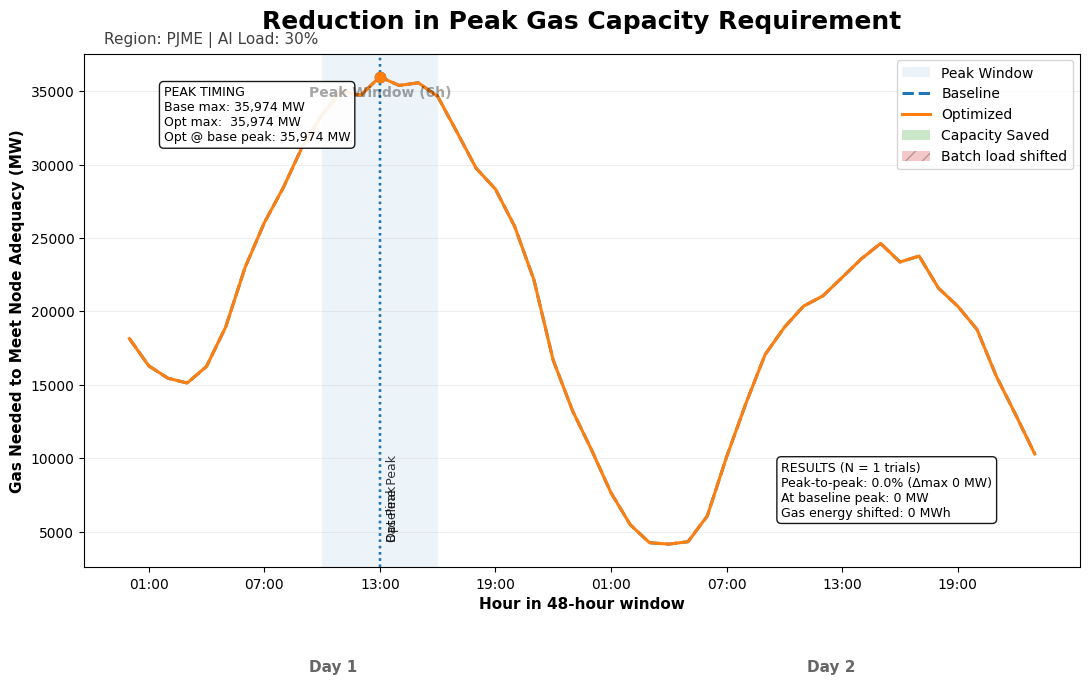

In [18]:
# @title Chart 1: Reduction in Peak Gas Capacity Requirement
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp
import matplotlib.patches as mpatches

# ==========
# SETTINGS
# ==========
BASE_DIR = globals().get(
    "BASE_DIR",
    "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
)

REGION = "PJME"
AI_FRAC = 0.30
TRIAL = 0

# Match your solver-style adequacy framing
STRESS_ALPHA = globals().get("STRESS_ALPHA", 0.2)      # used as C_non = alpha * max(L_base) (same as solve_milp)
RHO = globals().get("RHO", 0.15)
IMPORT_LIMIT_MW = globals().get("IMPORT_LIMIT_MW", 0.0)

# Peak window to highlight (hours)
PEAK_WINDOW_H = 6

# Solver / speed knobs
WATER_WEIGHT_FOR_OPT = 0.0  # "optimize gas only" in your objective when weight=0
TIME_LIMIT_S = 30
MAX_JOBS = 300              # IMPORTANT: raise for fidelity, lower if solver is slow

# ==========
# LOAD DATA
# ==========
windows_df = pd.read_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"))
workloads_df = pd.read_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"))

region_window = windows_df[windows_df["region"] == REGION].sort_values("hour_idx")
L_base = region_window["L_base_MW"].to_numpy()
T = len(L_base)
L_max = float(L_base.max())

# Your notebook’s online AI load shape (diurnal + noise) :contentReference[oaicite:2]{index=2}
rng = np.random.default_rng(TRIAL)
base_ai = L_max * AI_FRAC * 0.5
diurnal = 0.2 * base_ai * np.sin(np.linspace(0, 2*np.pi, T))
noise = rng.normal(0, 0.05 * base_ai, T)
L_online = np.clip(base_ai + diurnal + noise, 0, None)

jobs_df = workloads_df[
    (workloads_df["region"] == REGION) &
    (workloads_df["ai_fraction"] == AI_FRAC) &
    (workloads_df["trial"] == TRIAL)
].copy()

if MAX_JOBS is not None and len(jobs_df) > MAX_JOBS:
    jobs_df = jobs_df.sample(MAX_JOBS, random_state=0)

jobs = jobs_df[["id", "p", "d", "r", "e"]].to_dict("records")

# ==========
# HELPERS
# ==========
def schedule_baseline_asap(jobs, T):
    """
    Baseline = run each job as early as possible within [r,e) for d hours.
    This naturally piles load near the arrival peak (your generator centers arrivals near t_peak). :contentReference[oaicite:3]{index=3}
    """
    deferr = np.zeros(T)
    for j in jobs:
        p = float(j["p"])
        d = int(j["d"])
        r = int(j["r"])
        e = int(j["e"])
        start = r
        if start + d > e:
            start = max(r, e - d)  # latest feasible within window
        for t in range(start, start + d):
            if 0 <= t < T:
                deferr[t] += p
    return deferr

def solve_milp_with_schedule(L_base, L_online, jobs, alpha=0.2, rho=0.15, water_weight=0.0, import_limit_MW=0.0, time_limit=30):
    """
    Same structure as your solve_milp, but returns the actual per-hour deferrable schedule.
    Adequacy: L_total*(1+rho) <= C_non + C_gas + imports  :contentReference[oaicite:4]{index=4}
    Jobs: sum x[j,t] over [r,e) == d and 0 outside            :contentReference[oaicite:5]{index=5}
    """
    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex_Schedule", pulp.LpMinimize)

    C_gas = pulp.LpVariable("C_gas", lowBound=0)
    W_peak = pulp.LpVariable("W_peak", lowBound=0)

    x = pulp.LpVariable.dicts(
        "x",
        ((j["id"], t) for j in jobs for t in range(T)),
        cat=pulp.LpBinary
    )

    prob += C_gas + (water_weight * W_peak)

    C_non = alpha * float(np.max(L_base))

    # Constraints
    for t in range(T):
        ai_def = pulp.lpSum([float(j["p"]) * x[(j["id"], t)] for j in jobs])
        L_tot = float(L_base[t]) + float(L_online[t]) + ai_def

        prob += L_tot * (1 + rho) <= C_non + C_gas + import_limit_MW
        # keep W_peak for completeness (even if weight=0)
        # If you have w_vec, you can plug it in here; for this gas plot it’s not needed.

    for j in jobs:
        jid = j["id"]
        r, e, d = int(j["r"]), int(j["e"]), int(j["d"])
        prob += pulp.lpSum([x[(jid, t)] for t in range(r, e)]) == d
        prob += pulp.lpSum([x[(jid, t)] for t in range(T) if (t < r or t >= e)]) == 0

    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=time_limit)
    prob.solve(solver)
    status = pulp.LpStatus[prob.status]

    deferr = np.zeros(T)
    if status in ("Optimal", "Not Solved"):
        for j in jobs:
            jid = j["id"]
            p = float(j["p"])
            for t in range(T):
                v = pulp.value(x[(jid, t)])
                if v is not None and v > 0.5:
                    deferr[t] += p

    return {"status": status, "deferr_mw": deferr, "C_gas": pulp.value(C_gas), "W_peak": pulp.value(W_peak)}

def hourly_gas_needed(L_base, L_online, L_def, alpha=0.2, rho=0.15, import_limit_MW=0.0):
    """
    Per-hour implied gas requirement to satisfy adequacy:
    gas(t) = max(0, (L_total(t)*(1+rho) - C_non - imports))
    """
    C_non = alpha * float(np.max(L_base))
    L_total = L_base + L_online + L_def
    return np.maximum(0.0, L_total * (1 + rho) - C_non - import_limit_MW)

def plot_peak_gas_reduction(gas_base, gas_opt, region="PJME", ai_frac=0.30, peak_window_h=6):
    hours = np.arange(len(gas_base))

    base_peak_t = int(np.argmax(gas_base))
    opt_peak_t  = int(np.argmax(gas_opt))

    base_max = float(gas_base[base_peak_t])
    opt_max  = float(gas_opt[opt_peak_t])
    opt_at_base_peak = float(gas_opt[base_peak_t])

    delta_max = base_max - opt_max
    delta_at_base_peak = base_max - opt_at_base_peak
    pct = (delta_max / base_max * 100.0) if base_max > 0 else 0.0

    # “Energy shifted” = extra gas-hours where optimized exceeds baseline
    shifted_mwh = float(np.sum(np.clip(gas_opt - gas_base, 0, None))) * 1.0

    # Peak window span (centered on baseline peak)
    half = peak_window_h // 2
    start = max(0, base_peak_t - half)
    end = min(len(hours), start + peak_window_h)

    fig, ax = plt.subplots(figsize=(11, 7))

    # Peak window shading
    ax.axvspan(start, end, alpha=0.08, label="Peak Window")

    # Lines
    ax.plot(hours, gas_base, linestyle="--", linewidth=2.2, label="Baseline")
    ax.plot(hours, gas_opt, linewidth=2.2, label="Optimized")

    # Mark peaks + vertical lines
    ax.scatter([base_peak_t], [base_max], s=55, zorder=5)
    ax.scatter([opt_peak_t],  [opt_max],  s=55, zorder=5)

    ax.axvline(base_peak_t, linestyle=":", linewidth=1.7)
    ax.axvline(opt_peak_t,  linestyle=":", linewidth=1.7)

    ax.text(base_peak_t + 0.3, ax.get_ylim()[0] + 0.05*(ax.get_ylim()[1]-ax.get_ylim()[0]),
            "Baseline Peak", rotation=90, va="bottom", ha="left", fontsize=9, alpha=0.8)
    ax.text(opt_peak_t + 0.3, ax.get_ylim()[0] + 0.05*(ax.get_ylim()[1]-ax.get_ylim()[0]),
            "Opt Peak", rotation=90, va="bottom", ha="left", fontsize=9, alpha=0.8)

    # Capacity saved fill (only in peak window)
    in_window = (hours >= start) & (hours < end)
    saved_mask = in_window & (gas_base > gas_opt)
    ax.fill_between(hours, gas_opt, gas_base, where=saved_mask, alpha=0.25, label="Capacity Saved")

    # Load shifted hatch (where optimized > baseline)
    shifted_mask = gas_opt > gas_base
    ax.fill_between(hours, gas_base, gas_opt, where=shifted_mask,
                    alpha=0.25, hatch="//", edgecolor="k", linewidth=0.0, label="Batch load shifted")

    # Titles
    ax.set_title("Reduction in Peak Gas Capacity Requirement", fontsize=18, weight="bold", pad=18)
    ax.text(0.02, 1.02, f"Region: {region} | AI Load: {ai_frac:.0%}",
            transform=ax.transAxes, fontsize=11, alpha=0.75)

    # Peak timing box
    peak_txt = (
        "PEAK TIMING\n"
        f"Base max: {base_max:,.0f} MW\n"
        f"Opt max:  {opt_max:,.0f} MW\n"
        f"Opt @ base peak: {opt_at_base_peak:,.0f} MW"
    )
    ax.text(0.08, 0.83, peak_txt, transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.9))

    # Results box
    res_txt = (
        f"RESULTS (N = 1 trials)\n"
        f"Peak-to-peak: {pct:.1f}% (Δmax {delta_max:,.0f} MW)\n"
        f"At baseline peak: {delta_at_base_peak:,.0f} MW\n"
        f"Gas energy shifted: {shifted_mwh:,.0f} MWh"
    )
    ax.text(0.70, 0.10, res_txt, transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.9))

    # Peak window label
    ax.text((start+end)/2, ax.get_ylim()[1]*0.93, f"Peak Window ({peak_window_h}h)",
            ha="center", va="center", fontsize=10, weight="bold", alpha=0.35)

    # Axes labels
    ax.set_ylabel("Gas Needed to Meet Node Adequacy (MW)", fontsize=11, weight="bold")
    ax.set_xlabel("Hour in 48-hour window", fontsize=11, weight="bold")
    ax.grid(True, axis="y", alpha=0.2)

    # Nice time ticks (01:00, 07:00, 13:00, 19:00 for both days)
    tick_pos = [1, 7, 13, 19, 25, 31, 37, 43]
    tick_lab = ["01:00", "07:00", "13:00", "19:00", "01:00", "07:00", "13:00", "19:00"]
    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_lab)

    # Day labels under axis
    ax.text(0.25, -0.18, "Day 1", transform=ax.transAxes, ha="center", va="top",
            fontsize=11, weight="bold", alpha=0.6)
    ax.text(0.75, -0.18, "Day 2", transform=ax.transAxes, ha="center", va="top",
            fontsize=11, weight="bold", alpha=0.6)

    # Legend (clean)
    ax.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.show()

# ==========
# BUILD SERIES + PLOT
# ==========
# Baseline (no optimization): ASAP within each job’s [r,e)
def_base = schedule_baseline_asap(jobs, T)

# Optimized: MILP schedule (water_weight=0 => gas-only objective)
sol = solve_milp_with_schedule(
    L_base, L_online, jobs,
    alpha=STRESS_ALPHA, rho=RHO,
    water_weight=WATER_WEIGHT_FOR_OPT,
    import_limit_MW=IMPORT_LIMIT_MW,
    time_limit=TIME_LIMIT_S
)
print("MILP status:", sol["status"])

def_opt = sol["deferr_mw"]

gas_base = hourly_gas_needed(L_base, L_online, def_base, alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW)
gas_opt  = hourly_gas_needed(L_base, L_online, def_opt,  alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW)

plot_peak_gas_reduction(gas_base, gas_opt, region=REGION, ai_frac=AI_FRAC, peak_window_h=PEAK_WINDOW_H)

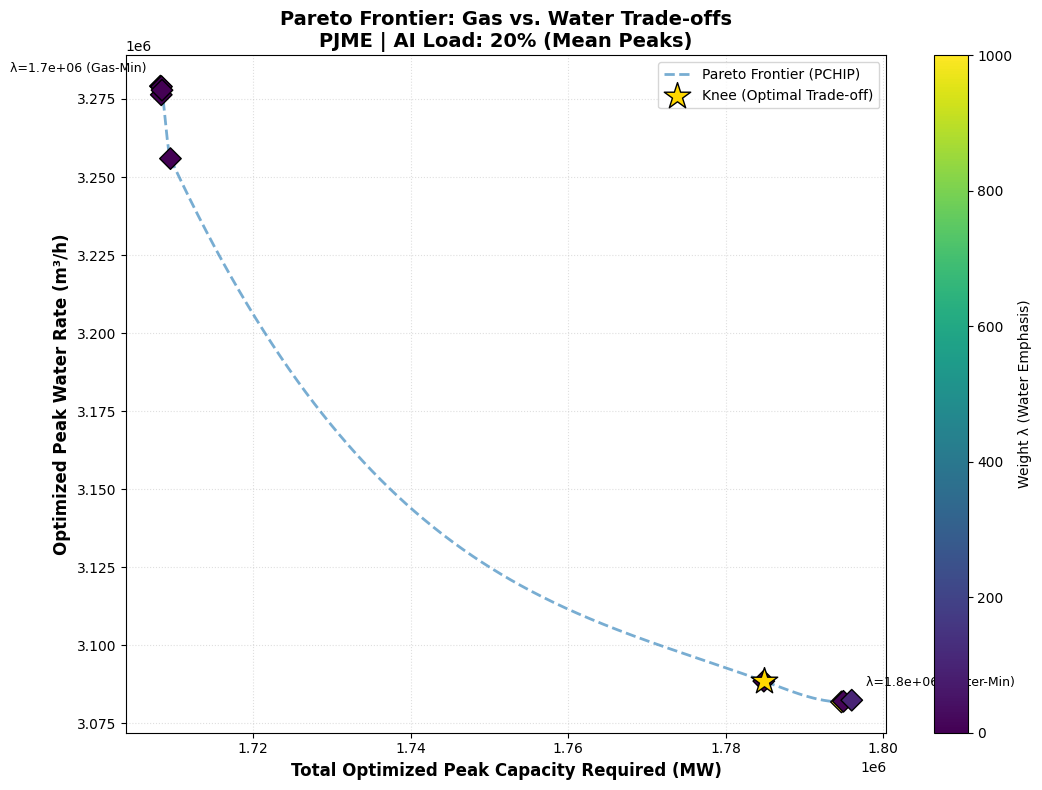

In [7]:
# @title 7. PARETO FRONTIER VISUALIZATION
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
import os

# 1. Load the optimized results
res_path = os.path.join(BASE_DIR, RESULTS_FILE)
if not os.path.exists(res_path):
    raise FileNotFoundError(f"Results file not found at {res_path}. Please run Cell 6 first.")

df = pd.read_csv(res_path)

# 2. Filter for the specific scenario to plot
target_region = df['region'].unique()[0]
target_ai = df['ai_fraction'].max()  # Usually 0.30/30% AI load
plot_df = df[(df['region'] == target_region) & (df['ai_fraction'] == target_ai)].copy()

# 3. Aggregate Trial Data (Mean across N=50)
summary = plot_df.groupby('water_weight').agg({
    'total_peak_mw': 'mean',
    'water_peak_m3h': 'mean'
}).reset_index().sort_values('total_peak_mw')

# Clean duplicates to ensure strictly increasing X for PCHIP
summary = summary.drop_duplicates(subset=['total_peak_mw'], keep='last')
x = summary['total_peak_mw'].values
y = summary['water_peak_m3h'].values

# 4. Visualization Logic
plt.figure(figsize=(11, 8), dpi=100)
ax = plt.gca()

if len(x) >= 3:
    # Generate smooth PCHIP curve
    x_smooth = np.linspace(x.min(), x.max(), 500)
    pchip = PchipInterpolator(x, y)
    y_smooth = pchip(x_smooth)
    plt.plot(x_smooth, y_smooth, 'tab:blue', linestyle='--', linewidth=2, alpha=0.6, label='Pareto Frontier (PCHIP)')

    # Automated "Knee" Detection (Normalizing to find max curvature)
    x_norm = (x - x.min()) / (x.max() - x.min())
    y_norm = (y - y.min()) / (y.max() - y.min())
    knee_idx = np.argmin(np.sqrt(x_norm**2 + y_norm**2))
    plt.scatter(x[knee_idx], y[knee_idx], color='gold', marker='*', s=400, edgecolors='black', zorder=10, label='Knee (Optimal Trade-off)')
else:
    plt.plot(x, y, 'tab:blue', linestyle='--', alpha=0.6)

# Scatter plot of individual weights
sc = plt.scatter(x, y, c=summary['water_weight'], cmap='viridis', s=120, marker='D', edgecolors='k', zorder=5)

# 5. Formatting
plt.title(f"Pareto Frontier: Gas vs. Water Trade-offs\n{target_region} | AI Load: {int(target_ai*100)}% (Mean Peaks)", fontsize=14, fontweight='bold')
plt.xlabel("Total Optimized Peak Capacity Required (MW)", fontsize=12, fontweight='bold')
plt.ylabel("Optimized Peak Water Rate (m³/h)", fontsize=12, fontweight='bold')
plt.colorbar(sc, label='Weight λ (Water Emphasis)')
plt.grid(True, which='both', linestyle=':', alpha=0.4)
plt.legend()

# Endpoint Annotations
plt.annotate(f'λ={x[0]:.1e} (Gas-Min)', (x[0], y[0]), textcoords="offset points", xytext=(-10,10), ha='right', fontsize=9)
plt.annotate(f'λ={x[-1]:.1e} (Water-Min)', (x[-1], y[-1]), textcoords="offset points", xytext=(10,10), ha='left', fontsize=9)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


ValueError: Axis limits cannot be NaN or Inf

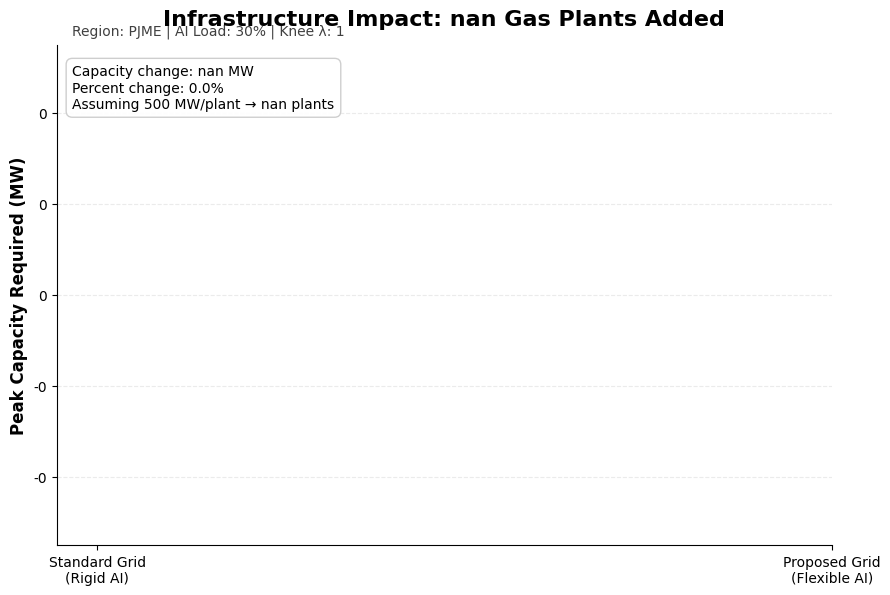

In [12]:
# @title 8. IMPACT CHART: POWER PLANTS AVOIDED (Rigid baseline = jobs fixed at release)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------- Inputs you already have ----------
# summary, knee_idx, PLANT_SIZE_MW, BASE_DIR, STRESS_ALPHA, IMPORT_LIMIT_MW
# windows_df, workloads_df should already exist in your notebook from the main loop

# 1. Load Pre-calculated Data
windows_df = pd.read_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"))
workloads_df = pd.read_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"))

RHO = globals().get("RHO", 0.15)

# Infer scenario from summary (or override)
REGION = str(summary["region"].iloc[0]) if "region" in summary.columns else "PJME"
AI_FRAC = float(summary["ai_fraction"].iloc[0]) if "ai_fraction" in summary.columns else 0.30

knee_weight = float(summary.iloc[knee_idx]["water_weight"])  # the λ at the knee

# ---------- Helper functions ----------
def build_online_ai_load(T, L_max, ai_frac, trial_seed):
    # Same structure as your notebook :contentReference[oaicite:2]{index=2}
    rng = np.random.default_rng(trial_seed)
    base_ai = L_max * ai_frac * 0.5
    diurnal = 0.2 * base_ai * np.sin(np.linspace(0, 2*np.pi, T))
    noise = rng.normal(0, 0.05 * base_ai, T)
    return np.clip(base_ai + diurnal + noise, 0, None)

def rigid_deferrable_profile(jobs, T):
    """
    RIGID baseline: jobs run at their release time for d hours (no shifting).
    """
    prof = np.zeros(T)
    for j in jobs:
        r = int(j["r"]); d = int(j["d"]); p = float(j["p"])
        for t in range(r, min(T, r + d)):
            prof[t] += p
    return prof

def required_capacity_mw(L_base, L_online, L_def, alpha, rho, import_limit):
    """
    Adequacy in your solver: L_total*(1+rho) <= C_non + C_gas + imports :contentReference[oaicite:3]{index=3}
    With C_non = alpha * max(L_base) in solve_milp :contentReference[oaicite:4]{index=4}
    Minimizing C_gas => C_gas = max_t( L_total*(1+rho) - C_non - imports, 0 )
    """
    L_max = float(np.max(L_base))
    C_non = alpha * L_max
    L_total = L_base + L_online + L_def
    C_gas = float(np.max(np.maximum(0.0, L_total * (1 + rho) - C_non - import_limit)))
    return C_non + C_gas  # total peak capacity required

# ---------- Pull the window ----------
region_window = windows_df[windows_df["region"] == REGION].sort_values("hour_idx")
L_base = region_window["L_base_MW"].to_numpy()
w_vec  = region_window["water_m3_per_mwh"].to_numpy()
T = len(L_base)
L_max = float(np.max(L_base))

# ---------- Compute rigid vs flexible over the same trials ----------
trial_ids = sorted(workloads_df[
    (workloads_df["region"] == REGION) &
    (workloads_df["ai_fraction"] == AI_FRAC)
]["trial"].unique().tolist())

rigid_caps = []
flex_caps  = []

for trial in trial_ids:
    jobs_df = workloads_df[
        (workloads_df["region"] == REGION) &
        (workloads_df["ai_fraction"] == AI_FRAC) &
        (workloads_df["trial"] == trial)
    ].copy()

    jobs = jobs_df.to_dict("records")

    L_online = build_online_ai_load(T, L_max, AI_FRAC, trial_seed=int(trial))

    # Rigid: fixed at release (no flexibility)
    L_def_rigid = rigid_deferrable_profile(jobs, T)
    cap_rigid = required_capacity_mw(L_base, L_online, L_def_rigid,
                                     alpha=STRESS_ALPHA, rho=RHO, import_limit=IMPORT_LIMIT_MW)
    rigid_caps.append(cap_rigid)

    # Flexible: MILP at knee weight (your actual optimized case)
    sol = solve_milp(L_base, L_online, jobs, w_vec,
                    alpha=STRESS_ALPHA, rho=RHO, water_weight=knee_weight,
                    include_thermal=False, import_limit_MW=IMPORT_LIMIT_MW)
    cap_flex = (STRESS_ALPHA * L_max) + float(sol["C_peak"])  # consistent with solver C_non :contentReference[oaicite:5]{index=5}
    flex_caps.append(cap_flex)

baseline_mw = float(np.mean(rigid_caps))
proposed_mw = float(np.mean(flex_caps))

mw_saved_signed = baseline_mw - proposed_mw
mw_saved = abs(mw_saved_signed)
pct_saved = (mw_saved / baseline_mw * 100.0) if baseline_mw > 0 else 0.0
plants_saved = mw_saved / PLANT_SIZE_MW

impact_word = "Gas Plants Avoided" if mw_saved_signed >= 0 else "Gas Plants Added"

# ---------- Pretty bar plot ----------
# scale axis to GW if huge
max_val = max(baseline_mw, proposed_mw)
if max_val >= 100_000:
    div, unit = 1_000.0, "GW"
else:
    div, unit = 1.0, "MW"

vals = [baseline_mw/div, proposed_mw/div]
labels = ["Standard Grid\n(Rigid AI)", "Proposed Grid\n(Flexible AI)"]

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.25)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)

bars = ax.bar([0, 1], vals, width=0.72,
              color=["#d9534f", "#5cb85c"], edgecolor="black", linewidth=1.2)

ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xticks([0, 1], labels)
ax.set_ylabel(f"Peak Capacity Required ({unit})", fontsize=12, fontweight="bold")
ax.set_title(f"Infrastructure Impact: {plants_saved:.2f} {impact_word}", fontsize=16, fontweight="bold", pad=14)
ax.text(0.02, 1.02, f"Region: {REGION} | AI Load: {AI_FRAC:.0%} | Knee λ: {knee_weight:g}",
        transform=ax.transAxes, fontsize=10, alpha=0.75)

# MW labels on top
y_pad = 0.02 * max(vals) if max(vals) > 0 else 1
for b, raw in zip(bars, [baseline_mw, proposed_mw]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + y_pad,
            f"{raw:,.0f} MW", ha="center", va="bottom", fontsize=11, fontweight="bold")

# Δ bracket
y_br = max(vals) + 4*y_pad
h_br = 2.2*y_pad
ax.plot([0, 0, 1, 1], [y_br, y_br + h_br, y_br + h_br, y_br], color="black", linewidth=1.4)
ax.text(0.5, y_br + h_br + 0.6*y_pad,
        f"Δ {mw_saved:,.0f} MW  ({pct_saved:.1f}%)",
        ha="center", va="bottom", fontsize=11, fontweight="bold")

# Callout box (positive magnitude)
callout = (
    f"Capacity change: {mw_saved:,.0f} MW\n"
    f"Percent change: {pct_saved:.1f}%\n"
    f"Assuming {PLANT_SIZE_MW:,.0f} MW/plant → {plants_saved:.2f} plants"
)
ax.text(0.02, 0.96, callout, transform=ax.transAxes,
        ha="left", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor="0.8", alpha=0.95))

ax.set_ylim(0, y_br + h_br + 5*y_pad)
plt.tight_layout()
plt.show()




---



In [15]:
# @title 4. WORKLOAD GENERATION & SOLVER FUNCTIONS - OLD IGNORE
import pulp
import numpy as np
import pandas as pd

# ==========================================
# A. STOCHASTIC JOB GENERATOR
# ==========================================
def generate_jobs_stochastic(T, t_peak, L_max, rng,
                             base_rate=0.6, peak_amp=1.5, peak_sigma=8,
                             slack_regime="loose"):
    """
    Generates a list of AI training jobs with stochastic arrival and flexibility.
    - Arrival times follow a Gaussian distribution centered at t_peak.
    - Slack (flexibility) is determined by the slack_regime.
    """
    jobs = []

    # 1. Determine total number of jobs based on peak load scaling
    n_jobs = int(L_max * 0.1)  # Heuristic for AI fleet size

    # 2. Sample Arrival Times (Gaussian distribution around grid peak)
    arrivals = rng.normal(t_peak, peak_sigma, n_jobs)
    arrivals = np.clip(arrivals, 0, T-1).astype(int)

    # 3. Define Slack Ranges based on regime
    slack_map = {
        "tight": (1, 4),
        "medium": (6, 12),
        "loose": (12, 24) # Allows significant shifting to low-water hours
    }
    s_min, s_max = slack_map.get(slack_regime, (6, 12))

    for i in range(n_jobs):
        p_val = rng.uniform(0.01 * L_max, 0.05 * L_max) # Power demand per job
        d_val = rng.integers(2, 8)                       # Duration in hours
        release = arrivals[i]

        # Calculate deadline based on slack
        slack = rng.integers(s_min, s_max + 1)
        deadline = min(T, release + d_val + slack)

        jobs.append({
            "id": i,
            "p": p_val,
            "d": d_val,
            "r": release,
            "e": deadline
        })
    return jobs

# ==========================================
# B. MILP OPTIMIZATION SOLVER
# ==========================================
def solve_milp(L_base, L_online, jobs, w_vec,
               alpha=0.5, rho=0.15, water_weight=0.0,
               include_thermal=False, import_limit_MW=0.0):
    """
    Solves the Mixed-Integer Linear Program to minimize Gas Capacity and Water.
    Minimize: C_gas + (water_weight * W_peak).
    """
    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex", pulp.LpMinimize)

    # --- Variables ---
    C_gas = pulp.LpVariable("C_gas", lowBound=0) # Local Gas Capacity required
    W_peak = pulp.LpVariable("W_peak", lowBound=0) # Peak Water Intensity (m3/h)

    # Decision variable: x[j, t] = 1 if job j is running at time t
    x = pulp.LpVariable.dicts("x",
                              ((j['id'], t) for j in jobs for t in range(T)),
                              cat=pulp.LpBinary)

    # --- Objective Function ---
    # Minimizing the trade-off between gas infrastructure and peak water usage
    prob += C_gas + (water_weight * W_peak)

    # --- Constraints ---
    C_non = alpha * np.max(L_base) # Baseline non-gas capacity

    for t in range(T):
        # 1. Total Load Calculation
        ai_deferrable = pulp.lpSum([j['p'] * x[j['id'], t] for j in jobs])
        L_total = L_base[t] + L_online[t] + ai_deferrable

        # 2. Grid Adequacy Constraint
        # All demand must be met by (Non-gas + Local Gas + Imports)
        prob += L_total * (1 + rho) <= C_non + C_gas + import_limit_MW

        # 3. Water Peak Constraint
        # Tracks the maximum water consumption across the horizon
        prob += L_total * w_vec[t] <= W_peak

    # 4. Job Completion Constraints
    for j in jobs:
        # Every job must run for its required duration
        prob += pulp.lpSum([x[j['id'], t] for t in range(j['r'], j['e'])]) == j['d']

        # Job cannot run before release or after deadline
        prob += pulp.lpSum([x[j['id'], t] for t in range(T) if t < j['r'] or t >= j['e']]) == 0

    # --- Solve ---
    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=30) # 30s limit to keep loop moving
    #solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=30, fractionGap=0.01)
    prob.solve(solver)

    status = pulp.LpStatus[prob.status]
    return {
        "status": status,
        "C_peak": pulp.value(C_gas) if status == "Optimal" else None,
        "W_peak": pulp.value(W_peak) if status == "Optimal" else None
    }


##########################################################################

def solve_milp_with_schedule(L_base, L_online, jobs, alpha=0.2, rho=0.15,
                             water_weight=0.0, import_limit_MW=0.0):
    """
    Solves the MILP and returns the hourly deferrable load profile.
    Adequacy: L_total * (1 + rho) <= C_non + C_gas + Imports
    """
    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex_Schedule", pulp.LpMinimize)

    # Variables: Infrastructure and Job Timing
    C_gas = pulp.LpVariable("C_gas", lowBound=0)
    W_peak = pulp.LpVariable("W_peak", lowBound=0)
    x = pulp.LpVariable.dicts("x", ((j['id'], t) for j in jobs for t in range(T)), cat=pulp.LpBinary)

    # Objective: Minimize Gas Infrastructure + Weighted Peak Water [cite: 242, 260]
    prob += C_gas + (water_weight * W_peak)

    # Fixed Baseload Capacity [cite: 263]
    C_non = alpha * float(np.max(L_base))

    # 1. Grid Adequacy & Water Constraints per hour [cite: 264-274]
    for t in range(T):
        ai_def = pulp.lpSum([float(j["p"]) * x[(j["id"], t)] for j in jobs])
        L_tot = float(L_base[t]) + float(L_online[t]) + ai_def

        # Reliability Constraint: Total Load + 15% Margin [cite: 270]
        prob += L_tot * (1 + rho) <= C_non + C_gas + import_limit_MW

        # Peak Water Tracking [cite: 274]
        # (Assuming w_vec is available; if not, this tracks total MW)
        # prob += L_tot * w_vec[t] <= W_peak

    # 2. Job Completion & Timing Constraints [cite: 275-281]
    for j in jobs:
        jid = j["id"]
        r, e, d = int(j["r"]), int(j["e"]), int(j["d"])
        # Job must run for required duration within its [release, deadline] window
        prob += pulp.lpSum([x[(jid, t)] for t in range(r, e)]) == d
        # Job cannot run outside its allowed window
        prob += pulp.lpSum([x[(jid, t)] for t in range(T) if (t < r or t >= e)]) == 0

    # 3. Solve [cite: 283-285]
    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=30, fractionGap=0.01)
    prob.solve(solver)

    # 4. Extract Hourly Profile
    deferr_profile = np.zeros(T)
    if pulp.LpStatus[prob.status] == "Optimal":
        for j in jobs:
            jid = j["id"]
            p = float(j["p"])
            for t in range(T):
                if pulp.value(x[(jid, t)]) > 0.5:
                    deferr_profile[t] += p

    return {
        "status": pulp.LpStatus[prob.status],
        "deferr_mw": deferr_profile,
        "C_peak": pulp.value(C_gas),
        "W_peak": pulp.value(W_peak)
    }

In [6]:
# @title 5. PRE-CALCULATION EXECUTION (RUN ONCE) - OLD IGNORE
import pandas as pd
import numpy as np
import os

# --- A. Pre-calculate Cleaned Windows ---
def run_window_precalc():
    print("=== Phase 1: Pre-calculating Regional Windows ===")
    window_results = []

    for region in REGIONS:
        try:
            print("region: ", region)
            print("HORIZON_HOURS: ", HORIZON_HOURS)
            # Uses functions from Cell 3
            load_df = load_ba_load(region)
            water_df = load_water_intensity(region)

            # Extracts the peak 72h window
            window = build_stressed_window(load_df, water_df, HORIZON_HOURS)

            window['region'] = region
            window['hour_idx'] = range(len(window))
            window_results.append(window)
            print(f"   [SUCCESS] Window ready for {region}")

        except Exception as e:
            print(f"   [ERROR] Could not process {region}: {e}")

    if window_results:
        final_windows_df = pd.concat(window_results)
        final_windows_df.to_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"), index=False)
        print("Done. Windows saved.")

# --- B. Pre-calculate Stochastic Workloads ---
def run_workload_precalc():
    print("\n=== Phase 2: Pre-calculating Stochastic Workloads ===")
    all_trial_jobs = []

    # Load the windows we just saved
    windows_path = os.path.join(BASE_DIR, "cleaned_regional_windows.csv")
    if not os.path.exists(windows_path):
        print("Error: Windows CSV missing. Run Phase 1 first.")
        return

    windows_df = pd.read_csv(windows_path)

    for region in REGIONS:
        region_window = windows_df[windows_df['region'] == region]
        L_base = region_window['L_base_MW'].values
        L_max = L_base.max()
        t_peak = np.argmax(L_base)
        T = len(L_base)

        for ai_frac in AI_LOAD_LEVELS:
            print(f"Generating {N_TRIALS} trials for {region} @ {ai_frac*100}% AI...")

            for trial in range(N_TRIALS):
                # Uses RNG from trial to ensure reproducibility
                rng = np.random.default_rng(trial)

                # Uses function from Cell 4 with SLACK_REGIME from Config
                jobs = generate_jobs_stochastic(T, t_peak, L_max, rng, slack_regime=SLACK_REGIME)

                temp_df = pd.DataFrame(jobs)
                temp_df['region'] = region
                temp_df['ai_fraction'] = ai_frac
                temp_df['trial'] = trial
                all_trial_jobs.append(temp_df)

    if all_trial_jobs:
        workload_df = pd.concat(all_trial_jobs)
        workload_df.to_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"), index=False)
        print("Done. Workloads saved.")

# Execute both
run_window_precalc()
run_workload_precalc()

=== Phase 1: Pre-calculating Regional Windows ===
region:  PJME
HORIZON_HOURS:  48
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak 48h Window...
      Selected window starting 2006-08-04 02:00:00 (Rank #1)
   [SUCCESS] Window ready for PJME
Done. Windows saved.

=== Phase 2: Pre-calculating Stochastic Workloads ===
Generating 2 trials for PJME @ 10.0% AI...
Generating 2 trials for PJME @ 20.0% AI...
Done. Workloads saved.


In [63]:
# @title 6. SPEED-OPTIMIZED MAIN LOOP - OLD IGNORE
import pandas as pd
import numpy as np
import os

# --- Helper Function: Non-Deferrable AI Load ---
def build_online_ai_load(window_df, L_max, ai_frac, rng):
    """Generates the base 'always-on' AI load with stochastic noise."""
    T = len(window_df)
    # Base load is a fraction of the regional max load
    base_ai = L_max * ai_frac * 0.5
    # Add diurnal variation + 5% white noise
    diurnal = 0.2 * base_ai * np.sin(np.linspace(0, 2*np.pi, T))
    noise = rng.normal(0, 0.05 * base_ai, T)
    return np.clip(base_ai + diurnal + noise, 0, None)

print("\n=== STARTING OPTIMIZED PARETO STUDY ===")

# 1. Load Pre-calculated Data
windows_df = pd.read_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"))
workloads_df = pd.read_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"))

results = []

for region in REGIONS:
    print(f"\nProcessing Region: {region}...")

    # Extract pre-cleaned window
    region_window = windows_df[windows_df['region'] == region].sort_values('hour_idx')
    L_base = region_window['L_base_MW'].values
    w_vec = region_window['water_m3_per_mwh'].values
    L_max = L_base.max()

    # Calculate fixed non-gas capacity based on STRESS_ALPHA
    c_non_val = (1.0 - STRESS_ALPHA) * L_max

    for ai_frac in AI_LOAD_LEVELS:
        print(f" -> AI Level: {int(ai_frac*100)}%")

        for trial in range(N_TRIALS):
            print(f"\nProcessing Trial: {trial}...")
            # Load the EXACT pre-generated workload for this trial
            trial_jobs_df = workloads_df[
                (workloads_df['region'] == region) &
                (workloads_df['ai_fraction'] == ai_frac) &
                (workloads_df['trial'] == trial)
            ]

            # Convert to list of dicts for the solver
            trial_jobs = trial_jobs_df.to_dict('records')

            # Generate the non-deferrable component
            rng = np.random.default_rng(trial)
            L_online = build_online_ai_load(region_window, L_max, ai_frac, rng)

            for w_weight in PARETO_WEIGHTS:
                print(f"\nProcessing PARETO WEIGHT: {w_weight}...")
                # RUN SOLVER
                # import_limit_MW is set to 0.0 to force local gas trade-offs
                sol = solve_milp(
                    L_base, L_online, trial_jobs, w_vec,
                    alpha=STRESS_ALPHA,
                    water_weight=w_weight,
                    include_thermal=False,
                    import_limit_MW=IMPORT_LIMIT_MW
                )

                if sol["status"] == "Optimal":
                    results.append({
                        "region": region,
                        "ai_fraction": ai_frac,
                        "trial": trial,
                        "water_weight": w_weight,
                        "total_peak_mw": sol["C_peak"] + c_non_val, # The X-axis
                        "water_peak_m3h": sol["W_peak"]             # The Y-axis
                    })

# 2. Save Final Results
res_df = pd.DataFrame(results)
res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
print(f"\nSuccess! Results saved to {RESULTS_FILE}")


=== STARTING OPTIMIZED PARETO STUDY ===

Processing Region: PJME...
 -> AI Level: 10%

Processing Trial: 0...

Processing PARETO WEIGHT: 0.0...

Processing PARETO WEIGHT: 1e-05...

Processing PARETO WEIGHT: 0.0001...

Processing PARETO WEIGHT: 0.001...

Processing PARETO WEIGHT: 0.01...

Processing PARETO WEIGHT: 0.1...

Processing PARETO WEIGHT: 1.0...

Processing PARETO WEIGHT: 10.0...

Processing PARETO WEIGHT: 100.0...

Processing PARETO WEIGHT: 1000.0...

Processing Trial: 1...

Processing PARETO WEIGHT: 0.0...

Processing PARETO WEIGHT: 1e-05...

Processing PARETO WEIGHT: 0.0001...

Processing PARETO WEIGHT: 0.001...

Processing PARETO WEIGHT: 0.01...

Processing PARETO WEIGHT: 0.1...

Processing PARETO WEIGHT: 1.0...

Processing PARETO WEIGHT: 10.0...

Processing PARETO WEIGHT: 100.0...

Processing PARETO WEIGHT: 1000.0...
 -> AI Level: 20%

Processing Trial: 0...

Processing PARETO WEIGHT: 0.0...

Processing PARETO WEIGHT: 1e-05...

Processing PARETO WEIGHT: 0.0001...

Process



---



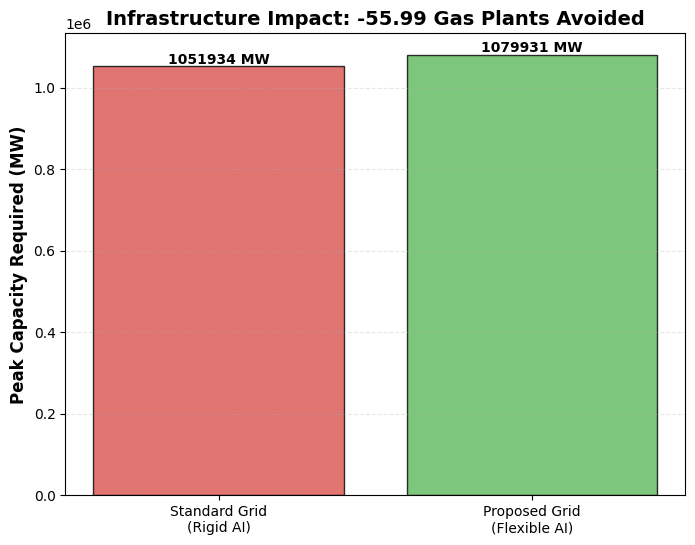

In [44]:
# @title 8. IMPACT CHART: POWER PLANTS AVOIDED
import seaborn as sns

# 1. Compare λ=0 (Gas-Only) vs λ=Knee (Optimal)
knee_data = summary.iloc[knee_idx]
gas_only_data = summary.iloc[0]

# 2. Calculate "Power Plants Avoided"
mw_saved = gas_only_data['total_peak_mw'] - knee_data['total_peak_mw']
plants_saved = mw_saved / PLANT_SIZE_MW

# 3. Create Visualization
plt.figure(figsize=(8, 6))
categories = ['Standard Grid\n(Rigid AI)', 'Proposed Grid\n(Flexible AI)']
values = [gas_only_data['total_peak_mw'], knee_data['total_peak_mw']]

bars = plt.bar(categories, values, color=['#d9534f', '#5cb85c'], edgecolor='black', alpha=0.8)
plt.ylabel("Peak Capacity Required (MW)", fontsize=12, fontweight='bold')
plt.title(f"Infrastructure Impact: {plants_saved:.2f} Gas Plants Avoided", fontsize=14, fontweight='bold')

# Add labels to bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 100, f'{int(yval)} MW', ha='center', va='bottom', fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

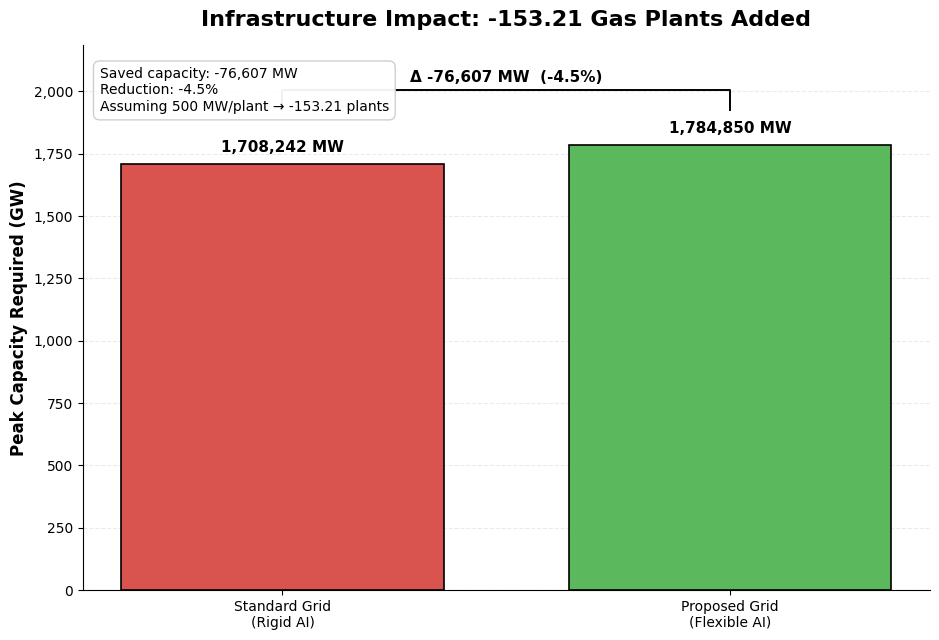

In [11]:
# @title 8. IMPACT CHART: POWER PLANTS AVOIDED (polished)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 1) Compare λ=0 (Gas-Only) vs λ=Knee (Optimal)
knee_data = summary.iloc[knee_idx]
gas_only_data = summary.iloc[0]

baseline_mw = float(gas_only_data["total_peak_mw"])
flex_mw     = float(knee_data["total_peak_mw"])

mw_saved = baseline_mw - flex_mw
pct_saved = (mw_saved / baseline_mw * 100.0) if baseline_mw > 0 else 0.0
plants_saved = mw_saved / PLANT_SIZE_MW

# If something flips (rare), make labeling robust
impact_word = "Gas Plants Avoided" if mw_saved >= 0 else "Gas Plants Added"

# 2) Auto-scale units so huge values don’t look like “1e6”
max_val = max(baseline_mw, flex_mw)
if max_val >= 100_000:   # show in GW when values are big
    div, unit = 1_000.0, "GW"
else:
    div, unit = 1.0, "MW"

baseline = baseline_mw / div
flex = flex_mw / div
saved = mw_saved / div
plant_unit = "plants"

# 3) Plot
fig, ax = plt.subplots(figsize=(9.5, 6.5))

labels = ["Standard Grid\n(Rigid AI)", "Proposed Grid\n(Flexible AI)"]
x = np.arange(len(labels))
values = [baseline, flex]

# nicer grid + minimal frame
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.25)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# bars
colors = ["#d9534f", "#5cb85c"]
bars = ax.bar(x, values, width=0.72, color=colors, edgecolor="black", linewidth=1.2, zorder=3)

# y formatting with commas
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

ax.set_ylabel(f"Peak Capacity Required ({unit})", fontsize=12, fontweight="bold")
ax.set_xticks(x, labels)
ax.set_title(
    f"Infrastructure Impact: {plants_saved:+.2f} {impact_word}",
    fontsize=16, fontweight="bold", pad=14
)

# 4) Value labels on bars
y_pad = 0.02 * max(values) if max(values) > 0 else 1
for b, raw_mw in zip(bars, [baseline_mw, flex_mw]):
    h = b.get_height()
    ax.text(
        b.get_x() + b.get_width()/2, h + y_pad,
        f"{raw_mw:,.0f} MW",
        ha="center", va="bottom",
        fontsize=11, fontweight="bold"
    )

# 5) Δ bracket between bars + Δ label
y_bracket = max(values) + 4*y_pad
h_bracket = 2.2*y_pad

# bracket shape
ax.plot([x[0], x[0], x[1], x[1]],
        [y_bracket, y_bracket + h_bracket, y_bracket + h_bracket, y_bracket],
        color="black", linewidth=1.4)

# delta label
delta_text = f"Δ {mw_saved:,.0f} MW  ({pct_saved:.1f}%)"
ax.text(
    np.mean(x), y_bracket + h_bracket + 0.6*y_pad,
    delta_text,
    ha="center", va="bottom",
    fontsize=11, fontweight="bold"
)

# 6) Callout box (saved MW, % and plants)
callout = (
    f"Saved capacity: {mw_saved:,.0f} MW\n"
    f"Reduction: {pct_saved:.1f}%\n"
    f"Assuming {PLANT_SIZE_MW:,.0f} MW/plant → {plants_saved:+.2f} {plant_unit}"
)
ax.text(
    0.02, 0.96, callout,
    transform=ax.transAxes,
    ha="left", va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor="0.8", alpha=0.95)
)

# 7) Better y-limits so labels/bracket fit
ax.set_ylim(0, y_bracket + h_bracket + 5*y_pad)

plt.tight_layout()
plt.show()


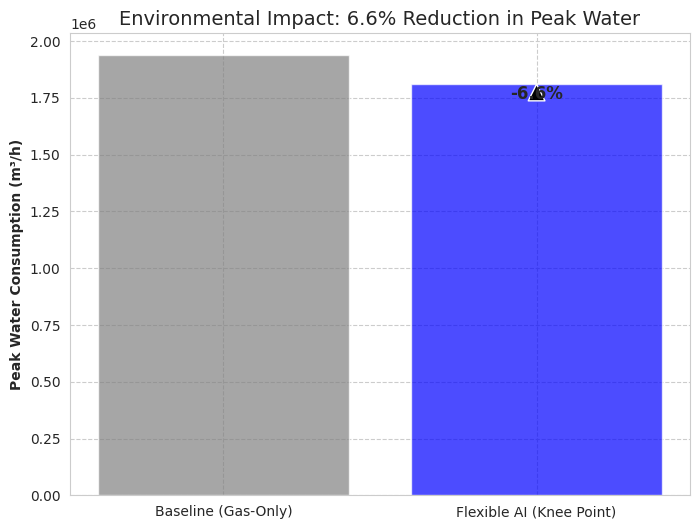

In [48]:
# @title 10. WATER SAVINGS IMPACT
# Calculate percentage reduction
base_water = summary.iloc[0]['water_peak_m3h']
knee_water = summary.iloc[knee_idx]['water_peak_m3h']
pct_reduction = ((base_water - knee_water) / base_water) * 100

plt.figure(figsize=(8, 6))
plt.bar(['Baseline (Gas-Only)', 'Flexible AI (Knee Point)'],
        [base_water, knee_water],
        color=['gray', 'blue'], alpha=0.7)

plt.ylabel("Peak Water Consumption (m³/h)", fontweight='bold')
plt.title(f"Environmental Impact: {pct_reduction:.1f}% Reduction in Peak Water", fontsize=14)
plt.annotate(f"-{pct_reduction:.1f}%", xy=(1, knee_water), xytext=(1, base_water*0.9),
             arrowprops=dict(facecolor='black', shrink=0.05), ha='center', fontsize=12, fontweight='bold')
plt.show()



---





---



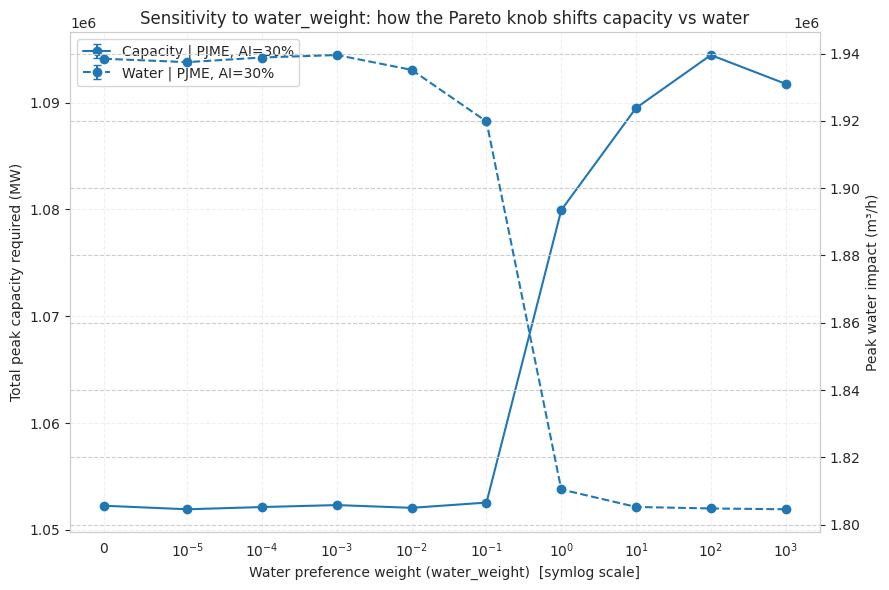

In [51]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses your existing config if it exists; otherwise falls back safely
BASE_DIR = globals().get(
    "BASE_DIR",
    "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
)
RESULTS_FILE = globals().get("RESULTS_FILE", "final_scientific_results_optimized.csv")

res_path = os.path.join(BASE_DIR, RESULTS_FILE)
df = pd.read_csv(res_path)

# Aggregate across trials for clean curves
agg = (df.groupby(["region", "ai_fraction", "water_weight"], as_index=False)
         .agg(
             cap_mean=("total_peak_mw", "mean"),
             cap_std=("total_peak_mw", "std"),
             water_mean=("water_peak_m3h", "mean"),
             water_std=("water_peak_m3h", "std"),
             n=("trial", "nunique"),
         ))
agg["cap_std"] = agg["cap_std"].fillna(0.0)
agg["water_std"] = agg["water_std"].fillna(0.0)

fig, ax1 = plt.subplots(figsize=(9, 6))
ax2 = ax1.twinx()

# Plot one line per (region, ai_fraction)
for (region, ai_frac), sub in agg.groupby(["region", "ai_fraction"]):
    sub = sub.sort_values("water_weight")

    # Use symlog so weight=0 is still visible
    x = sub["water_weight"].values

    ax1.errorbar(
        x, sub["cap_mean"],
        yerr=sub["cap_std"],
        fmt="-o", capsize=3,
        label=f"Capacity | {region}, AI={ai_frac:.0%}"
    )
    ax2.errorbar(
        x, sub["water_mean"],
        yerr=sub["water_std"],
        fmt="--o", capsize=3,
        label=f"Water | {region}, AI={ai_frac:.0%}"
    )

# Axis labels + scale
ax1.set_xscale("symlog", linthresh=1e-5)  # keeps 0 and tiny weights readable
ax1.set_xlabel("Water preference weight (water_weight)  [symlog scale]")
ax1.set_ylabel("Total peak capacity required (MW)")
ax2.set_ylabel("Peak water impact (m³/h)")

ax1.set_title("Sensitivity to water_weight: how the Pareto knob shifts capacity vs water")
ax1.grid(True, alpha=0.3)

# Build a combined legend
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="best")

plt.tight_layout()
plt.show()


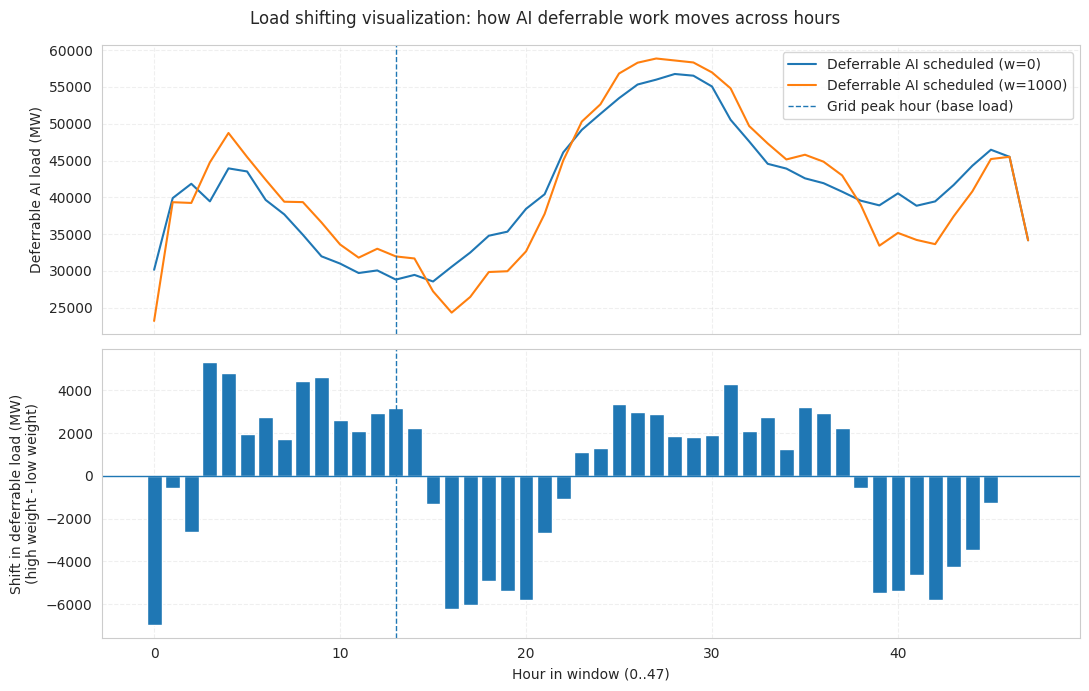

Solve status low weight: Optimal | C_gas: 96694.329 | W_peak: 203806.86
Solve status high weight: Optimal | C_gas: 100418.09 | W_peak: 191600.21


In [53]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp

# --- Load your precomputed inputs (from earlier cells) ---
BASE_DIR = globals().get(
    "BASE_DIR",
    "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
)

windows_df   = pd.read_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"))
workloads_df = pd.read_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"))

# --- Pick one scenario to visualize ---
REGION = "PJME"
AI_FRAC = 0.30
TRIAL = 0

W_LOW  = 0.0
W_HIGH = 1000.0  # strong water preference (edit if you want)

# For speed: downsample jobs for visualization (raise this if your solve is fast)
MAX_JOBS = 250

STRESS_ALPHA = globals().get("STRESS_ALPHA", 0.2)
IMPORT_LIMIT_MW = globals().get("IMPORT_LIMIT_MW", 0.0)
RHO = 0.15  # same as your solver default

# --- Extract window arrays ---
region_window = windows_df[(windows_df["region"] == REGION)].sort_values("hour_idx")
L_base = region_window["L_base_MW"].to_numpy()
w_vec  = region_window["water_m3_per_mwh"].to_numpy()
T = len(L_base)
L_max = float(L_base.max())
t_peak = int(np.argmax(L_base))

# --- Rebuild non-deferrable "online" AI load (same structure as your helper) ---
# (base_ai + diurnal + noise, clipped) :contentReference[oaicite:2]{index=2}
rng = np.random.default_rng(TRIAL)
base_ai = L_max * AI_FRAC * 0.5
diurnal = 0.2 * base_ai * np.sin(np.linspace(0, 2*np.pi, T))
noise = rng.normal(0, 0.05 * base_ai, T)
L_online = np.clip(base_ai + diurnal + noise, 0, None)

# --- Get jobs for this scenario ---
trial_jobs_df = workloads_df[
    (workloads_df["region"] == REGION) &
    (workloads_df["ai_fraction"] == AI_FRAC) &
    (workloads_df["trial"] == TRIAL)
].copy()

if MAX_JOBS is not None and len(trial_jobs_df) > MAX_JOBS:
    trial_jobs_df = trial_jobs_df.sample(MAX_JOBS, random_state=0)

jobs = trial_jobs_df[["id","p","d","r","e"]].to_dict("records")

def solve_milp_with_schedule(L_base, L_online, jobs, w_vec,
                            alpha=0.2, rho=0.15, water_weight=0.0,
                            import_limit_MW=0.0, time_limit=30):

    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex_Schedule", pulp.LpMinimize)

    C_gas  = pulp.LpVariable("C_gas", lowBound=0)
    W_peak = pulp.LpVariable("W_peak", lowBound=0)

    # Binary decisions x[j,t]
    x = {(j["id"], t): pulp.LpVariable(f"x_{j['id']}_{t}", cat="Binary")
         for j in jobs for t in range(T)}

    # Objective: gas capacity + weight * peak water
    prob += C_gas + (water_weight * W_peak)

    C_non = alpha * float(np.max(L_base))

    for t in range(T):
        ai_def = pulp.lpSum([j["p"] * x[(j["id"], t)] for j in jobs])
        L_tot  = float(L_base[t]) + float(L_online[t]) + ai_def

        # Adequacy: meet load with non-gas + gas + imports
        prob += L_tot * (1 + rho) <= C_non + C_gas + import_limit_MW

        # Water peak constraint
        prob += L_tot * float(w_vec[t]) <= W_peak

    # Job completion + feasibility window
    for j in jobs:
        r, e, d = int(j["r"]), int(j["e"]), int(j["d"])
        prob += pulp.lpSum([x[(j["id"], t)] for t in range(r, e)]) == d
        prob += pulp.lpSum([x[(j["id"], t)] for t in range(T) if (t < r or t >= e)]) == 0

    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=time_limit)
    prob.solve(solver)
    status = pulp.LpStatus[prob.status]

    # Build deferrable load time series from solution
    deferr = np.zeros(T)
    if status in ("Optimal", "Not Solved", "Infeasible", "Undefined"):
        # Only trust values if solver returned something; for "Optimal" it's best
        for j in jobs:
            jid = j["id"]
            p = float(j["p"])
            for t in range(T):
                val = pulp.value(x[(jid, t)])
                if val is not None and val > 0.5:
                    deferr[t] += p

    return {
        "status": status,
        "deferr_mw": deferr,
        "total_mw": (L_base + L_online + deferr),
        "C_gas": pulp.value(C_gas),
        "W_peak": pulp.value(W_peak),
    }

sol0 = solve_milp_with_schedule(L_base, L_online, jobs, w_vec,
                                alpha=STRESS_ALPHA, rho=RHO,
                                water_weight=W_LOW, import_limit_MW=IMPORT_LIMIT_MW)

solH = solve_milp_with_schedule(L_base, L_online, jobs, w_vec,
                                alpha=STRESS_ALPHA, rho=RHO,
                                water_weight=W_HIGH, import_limit_MW=IMPORT_LIMIT_MW)

hours = np.arange(T)
delta = solH["deferr_mw"] - sol0["deferr_mw"]

# --- Plot: scheduled deferrable load + the shift (difference) ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

ax1.plot(hours, sol0["deferr_mw"], label=f"Deferrable AI scheduled (w={W_LOW:g})")
ax1.plot(hours, solH["deferr_mw"], label=f"Deferrable AI scheduled (w={W_HIGH:g})")
ax1.axvline(t_peak, linestyle="--", linewidth=1, label="Grid peak hour (base load)")
ax1.set_ylabel("Deferrable AI load (MW)")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.bar(hours, delta)
ax2.axhline(0, linewidth=1)
ax2.axvline(t_peak, linestyle="--", linewidth=1)
ax2.set_xlabel("Hour in window (0..47)")
ax2.set_ylabel("Shift in deferrable load (MW)\n(high weight - low weight)")
ax2.grid(True, alpha=0.3)

plt.suptitle("Load shifting visualization: how AI deferrable work moves across hours")
plt.tight_layout()
plt.show()

print("Solve status low weight:", sol0["status"], "| C_gas:", sol0["C_gas"], "| W_peak:", sol0["W_peak"])
print("Solve status high weight:", solH["status"], "| C_gas:", solH["C_gas"], "| W_peak:", solH["W_peak"])


MILP status: Optimal


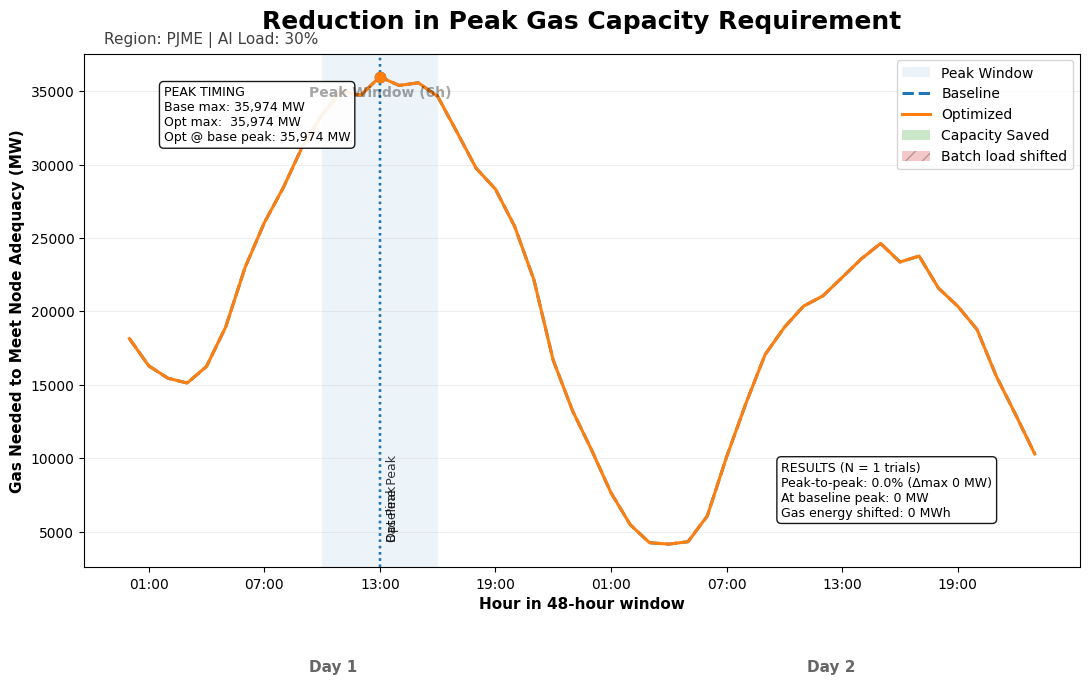

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp
import matplotlib.patches as mpatches

# ==========
# SETTINGS
# ==========
BASE_DIR = globals().get(
    "BASE_DIR",
    "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
)

REGION = "PJME"
AI_FRAC = 0.30
TRIAL = 0

# Match your solver-style adequacy framing
STRESS_ALPHA = globals().get("STRESS_ALPHA", 0.2)      # used as C_non = alpha * max(L_base) (same as solve_milp)
RHO = globals().get("RHO", 0.15)
IMPORT_LIMIT_MW = globals().get("IMPORT_LIMIT_MW", 0.0)

# Peak window to highlight (hours)
PEAK_WINDOW_H = 6

# Solver / speed knobs
WATER_WEIGHT_FOR_OPT = 0.0  # "optimize gas only" in your objective when weight=0
TIME_LIMIT_S = 30
MAX_JOBS = 300              # IMPORTANT: raise for fidelity, lower if solver is slow

# ==========
# LOAD DATA
# ==========
windows_df = pd.read_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"))
workloads_df = pd.read_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"))

region_window = windows_df[windows_df["region"] == REGION].sort_values("hour_idx")
L_base = region_window["L_base_MW"].to_numpy()
T = len(L_base)
L_max = float(L_base.max())

# Your notebook’s online AI load shape (diurnal + noise) :contentReference[oaicite:2]{index=2}
rng = np.random.default_rng(TRIAL)
base_ai = L_max * AI_FRAC * 0.5
diurnal = 0.2 * base_ai * np.sin(np.linspace(0, 2*np.pi, T))
noise = rng.normal(0, 0.05 * base_ai, T)
L_online = np.clip(base_ai + diurnal + noise, 0, None)

jobs_df = workloads_df[
    (workloads_df["region"] == REGION) &
    (workloads_df["ai_fraction"] == AI_FRAC) &
    (workloads_df["trial"] == TRIAL)
].copy()

if MAX_JOBS is not None and len(jobs_df) > MAX_JOBS:
    jobs_df = jobs_df.sample(MAX_JOBS, random_state=0)

jobs = jobs_df[["id", "p", "d", "r", "e"]].to_dict("records")

# ==========
# HELPERS
# ==========
def schedule_baseline_asap(jobs, T):
    """
    Baseline = run each job as early as possible within [r,e) for d hours.
    This naturally piles load near the arrival peak (your generator centers arrivals near t_peak). :contentReference[oaicite:3]{index=3}
    """
    deferr = np.zeros(T)
    for j in jobs:
        p = float(j["p"])
        d = int(j["d"])
        r = int(j["r"])
        e = int(j["e"])
        start = r
        if start + d > e:
            start = max(r, e - d)  # latest feasible within window
        for t in range(start, start + d):
            if 0 <= t < T:
                deferr[t] += p
    return deferr

def solve_milp_with_schedule(L_base, L_online, jobs, alpha=0.2, rho=0.15, water_weight=0.0, import_limit_MW=0.0, time_limit=30):
    """
    Same structure as your solve_milp, but returns the actual per-hour deferrable schedule.
    Adequacy: L_total*(1+rho) <= C_non + C_gas + imports  :contentReference[oaicite:4]{index=4}
    Jobs: sum x[j,t] over [r,e) == d and 0 outside            :contentReference[oaicite:5]{index=5}
    """
    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex_Schedule", pulp.LpMinimize)

    C_gas = pulp.LpVariable("C_gas", lowBound=0)
    W_peak = pulp.LpVariable("W_peak", lowBound=0)

    x = pulp.LpVariable.dicts(
        "x",
        ((j["id"], t) for j in jobs for t in range(T)),
        cat=pulp.LpBinary
    )

    prob += C_gas + (water_weight * W_peak)

    C_non = alpha * float(np.max(L_base))

    # Constraints
    for t in range(T):
        ai_def = pulp.lpSum([float(j["p"]) * x[(j["id"], t)] for j in jobs])
        L_tot = float(L_base[t]) + float(L_online[t]) + ai_def

        prob += L_tot * (1 + rho) <= C_non + C_gas + import_limit_MW
        # keep W_peak for completeness (even if weight=0)
        # If you have w_vec, you can plug it in here; for this gas plot it’s not needed.

    for j in jobs:
        jid = j["id"]
        r, e, d = int(j["r"]), int(j["e"]), int(j["d"])
        prob += pulp.lpSum([x[(jid, t)] for t in range(r, e)]) == d
        prob += pulp.lpSum([x[(jid, t)] for t in range(T) if (t < r or t >= e)]) == 0

    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=time_limit)
    prob.solve(solver)
    status = pulp.LpStatus[prob.status]

    deferr = np.zeros(T)
    if status in ("Optimal", "Not Solved"):
        for j in jobs:
            jid = j["id"]
            p = float(j["p"])
            for t in range(T):
                v = pulp.value(x[(jid, t)])
                if v is not None and v > 0.5:
                    deferr[t] += p

    return {"status": status, "deferr_mw": deferr, "C_gas": pulp.value(C_gas), "W_peak": pulp.value(W_peak)}

def hourly_gas_needed(L_base, L_online, L_def, alpha=0.2, rho=0.15, import_limit_MW=0.0):
    """
    Per-hour implied gas requirement to satisfy adequacy:
    gas(t) = max(0, (L_total(t)*(1+rho) - C_non - imports))
    """
    C_non = alpha * float(np.max(L_base))
    L_total = L_base + L_online + L_def
    return np.maximum(0.0, L_total * (1 + rho) - C_non - import_limit_MW)

def plot_peak_gas_reduction(gas_base, gas_opt, region="PJME", ai_frac=0.30, peak_window_h=6):
    hours = np.arange(len(gas_base))

    base_peak_t = int(np.argmax(gas_base))
    opt_peak_t  = int(np.argmax(gas_opt))

    base_max = float(gas_base[base_peak_t])
    opt_max  = float(gas_opt[opt_peak_t])
    opt_at_base_peak = float(gas_opt[base_peak_t])

    delta_max = base_max - opt_max
    delta_at_base_peak = base_max - opt_at_base_peak
    pct = (delta_max / base_max * 100.0) if base_max > 0 else 0.0

    # “Energy shifted” = extra gas-hours where optimized exceeds baseline
    shifted_mwh = float(np.sum(np.clip(gas_opt - gas_base, 0, None))) * 1.0

    # Peak window span (centered on baseline peak)
    half = peak_window_h // 2
    start = max(0, base_peak_t - half)
    end = min(len(hours), start + peak_window_h)

    fig, ax = plt.subplots(figsize=(11, 7))

    # Peak window shading
    ax.axvspan(start, end, alpha=0.08, label="Peak Window")

    # Lines
    ax.plot(hours, gas_base, linestyle="--", linewidth=2.2, label="Baseline")
    ax.plot(hours, gas_opt, linewidth=2.2, label="Optimized")

    # Mark peaks + vertical lines
    ax.scatter([base_peak_t], [base_max], s=55, zorder=5)
    ax.scatter([opt_peak_t],  [opt_max],  s=55, zorder=5)

    ax.axvline(base_peak_t, linestyle=":", linewidth=1.7)
    ax.axvline(opt_peak_t,  linestyle=":", linewidth=1.7)

    ax.text(base_peak_t + 0.3, ax.get_ylim()[0] + 0.05*(ax.get_ylim()[1]-ax.get_ylim()[0]),
            "Baseline Peak", rotation=90, va="bottom", ha="left", fontsize=9, alpha=0.8)
    ax.text(opt_peak_t + 0.3, ax.get_ylim()[0] + 0.05*(ax.get_ylim()[1]-ax.get_ylim()[0]),
            "Opt Peak", rotation=90, va="bottom", ha="left", fontsize=9, alpha=0.8)

    # Capacity saved fill (only in peak window)
    in_window = (hours >= start) & (hours < end)
    saved_mask = in_window & (gas_base > gas_opt)
    ax.fill_between(hours, gas_opt, gas_base, where=saved_mask, alpha=0.25, label="Capacity Saved")

    # Load shifted hatch (where optimized > baseline)
    shifted_mask = gas_opt > gas_base
    ax.fill_between(hours, gas_base, gas_opt, where=shifted_mask,
                    alpha=0.25, hatch="//", edgecolor="k", linewidth=0.0, label="Batch load shifted")

    # Titles
    ax.set_title("Reduction in Peak Gas Capacity Requirement", fontsize=18, weight="bold", pad=18)
    ax.text(0.02, 1.02, f"Region: {region} | AI Load: {ai_frac:.0%}",
            transform=ax.transAxes, fontsize=11, alpha=0.75)

    # Peak timing box
    peak_txt = (
        "PEAK TIMING\n"
        f"Base max: {base_max:,.0f} MW\n"
        f"Opt max:  {opt_max:,.0f} MW\n"
        f"Opt @ base peak: {opt_at_base_peak:,.0f} MW"
    )
    ax.text(0.08, 0.83, peak_txt, transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.9))

    # Results box
    res_txt = (
        f"RESULTS (N = 1 trials)\n"
        f"Peak-to-peak: {pct:.1f}% (Δmax {delta_max:,.0f} MW)\n"
        f"At baseline peak: {delta_at_base_peak:,.0f} MW\n"
        f"Gas energy shifted: {shifted_mwh:,.0f} MWh"
    )
    ax.text(0.70, 0.10, res_txt, transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.9))

    # Peak window label
    ax.text((start+end)/2, ax.get_ylim()[1]*0.93, f"Peak Window ({peak_window_h}h)",
            ha="center", va="center", fontsize=10, weight="bold", alpha=0.35)

    # Axes labels
    ax.set_ylabel("Gas Needed to Meet Node Adequacy (MW)", fontsize=11, weight="bold")
    ax.set_xlabel("Hour in 48-hour window", fontsize=11, weight="bold")
    ax.grid(True, axis="y", alpha=0.2)

    # Nice time ticks (01:00, 07:00, 13:00, 19:00 for both days)
    tick_pos = [1, 7, 13, 19, 25, 31, 37, 43]
    tick_lab = ["01:00", "07:00", "13:00", "19:00", "01:00", "07:00", "13:00", "19:00"]
    ax.set_xticks(tick_pos)
    ax.set_xticklabels(tick_lab)

    # Day labels under axis
    ax.text(0.25, -0.18, "Day 1", transform=ax.transAxes, ha="center", va="top",
            fontsize=11, weight="bold", alpha=0.6)
    ax.text(0.75, -0.18, "Day 2", transform=ax.transAxes, ha="center", va="top",
            fontsize=11, weight="bold", alpha=0.6)

    # Legend (clean)
    ax.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.show()

# ==========
# BUILD SERIES + PLOT
# ==========
# Baseline (no optimization): ASAP within each job’s [r,e)
def_base = schedule_baseline_asap(jobs, T)

# Optimized: MILP schedule (water_weight=0 => gas-only objective)
sol = solve_milp_with_schedule(
    L_base, L_online, jobs,
    alpha=STRESS_ALPHA, rho=RHO,
    water_weight=WATER_WEIGHT_FOR_OPT,
    import_limit_MW=IMPORT_LIMIT_MW,
    time_limit=TIME_LIMIT_S
)
print("MILP status:", sol["status"])

def_opt = sol["deferr_mw"]

gas_base = hourly_gas_needed(L_base, L_online, def_base, alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW)
gas_opt  = hourly_gas_needed(L_base, L_online, def_opt,  alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW)

plot_peak_gas_reduction(gas_base, gas_opt, region=REGION, ai_frac=AI_FRAC, peak_window_h=PEAK_WINDOW_H)
